Name

Labpartner(s)

In [1]:
#import statements go here
import numpy as np
import matplotlib.pyplot as plt

# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [2]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [4]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [5]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)])


In [6]:
# Now solve the system


# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [7]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [8]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [9]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [10]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [11]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [12]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

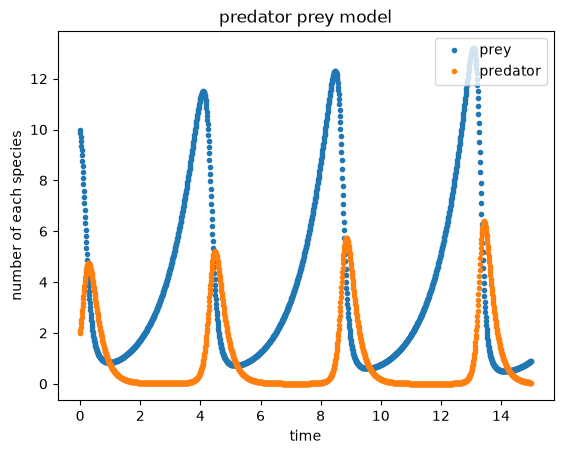

In [13]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

What happens if we start with different initial conditions? Like more prey and less predators.

In [14]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [15]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [16]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

What happened?

Text(0.5, 1.0, 'predator prey model')

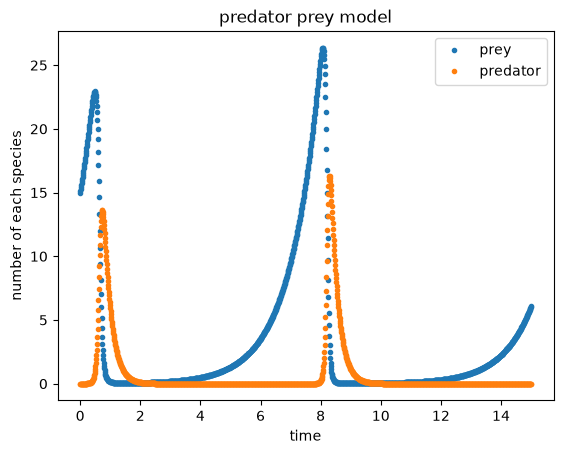

In [17]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What if we start with the same amount of prey and predators?

In [18]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [19]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [20]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

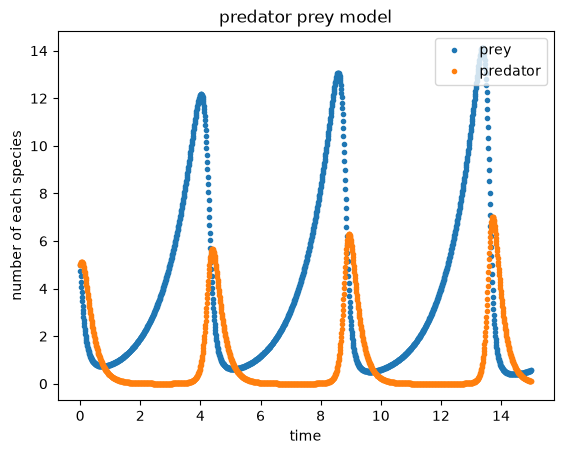

In [21]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

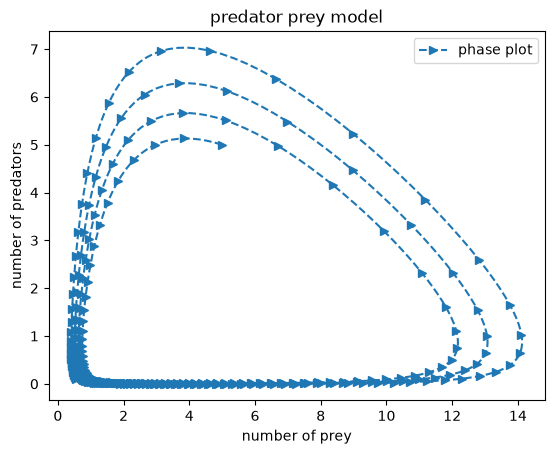

In [22]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

Let's mess around with the model parameters. What if the prey grow faster?

In [23]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [24]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 =5 # initial predator amount
t0 = 0.

In [25]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

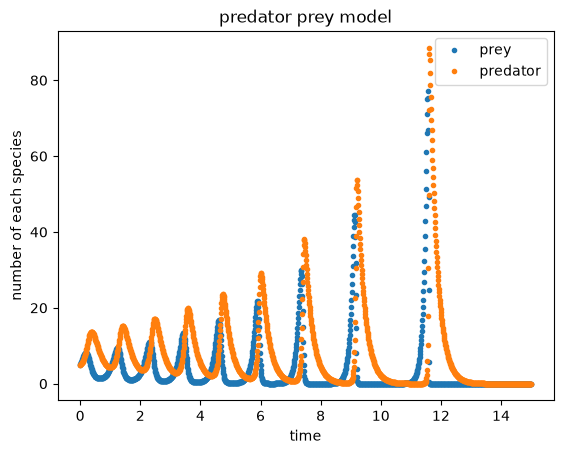

In [26]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

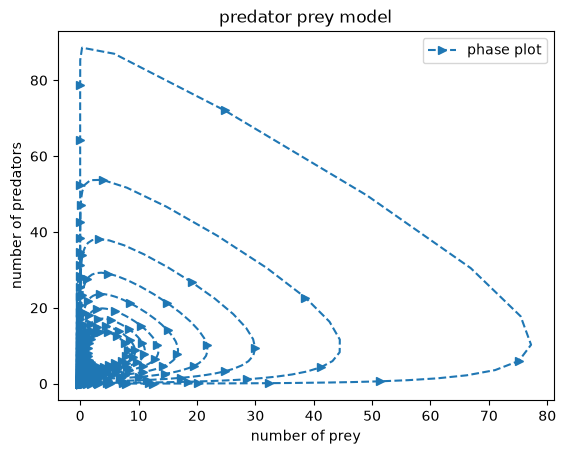

In [27]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

In [28]:
# reset parameters (lecture ended with alpha = 10)
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

T = 15.0
x0 = 10.
y0 = 2.

# function to run the model so I don't have to copy the loop every time
def run_model(step_method, dt):
    N = int(round(T/dt)) + 1   # need round, int(15/0.0001) gives 149999
    u = np.zeros((N, 2))
    u[0] = np.array([x0, y0])
    for n in range(N-1):
        u[n+1] = step_method(u[n], f, dt)
    t = np.linspace(0.0, T, N)
    return t, u

dt = 0.1: min prey = -4.68, max prey = 26.00, max predator = 21.21
dt = 0.01: min prey = 0.49, max prey = 13.22, max predator = 6.39
dt = 0.001: min prey = 0.86, max prey = 11.05, max predator = 4.79
dt = 0.0001: min prey = 0.90, max prey = 10.87, max predator = 4.66


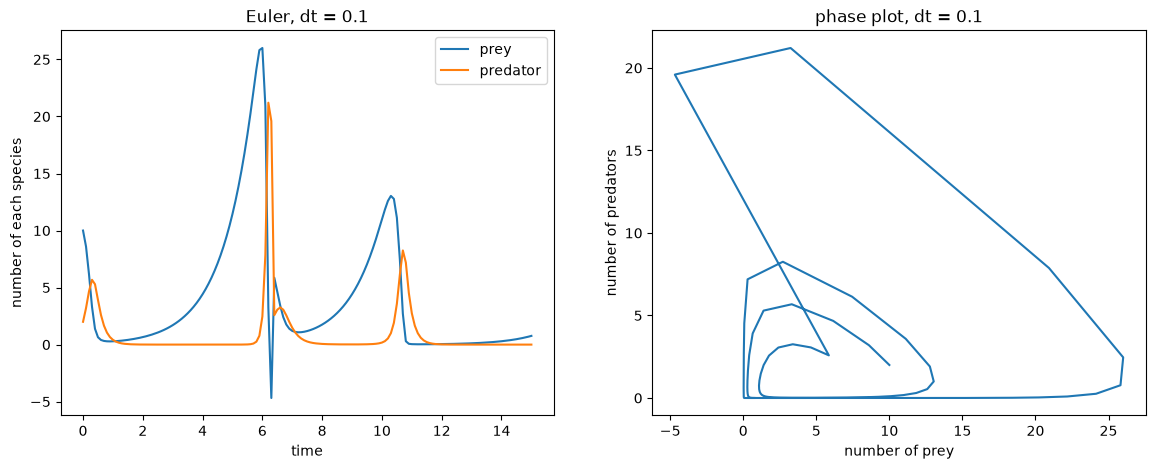

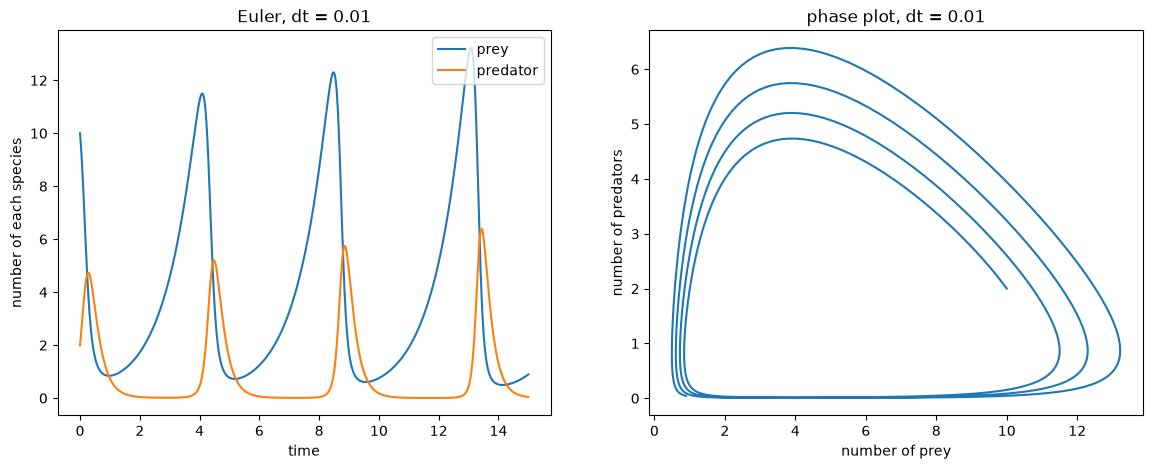

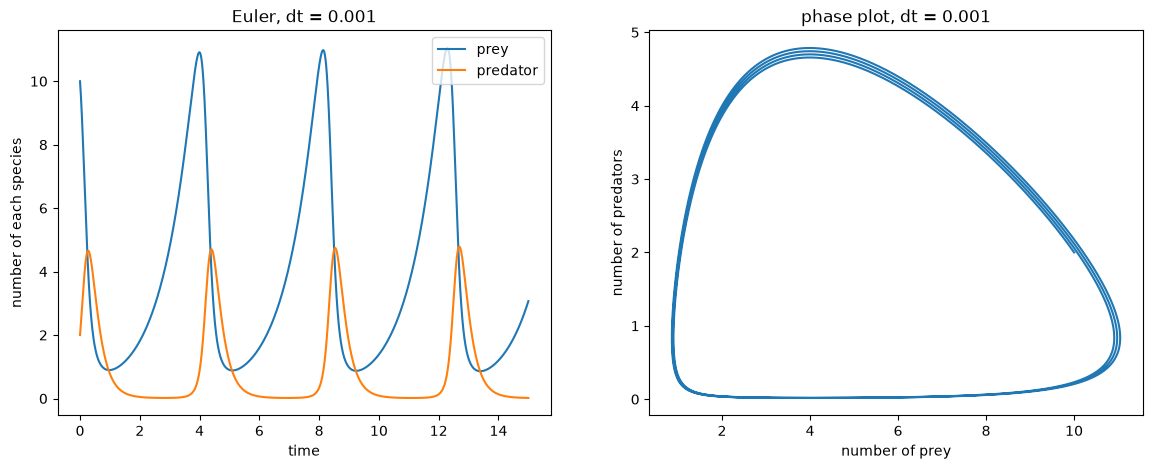

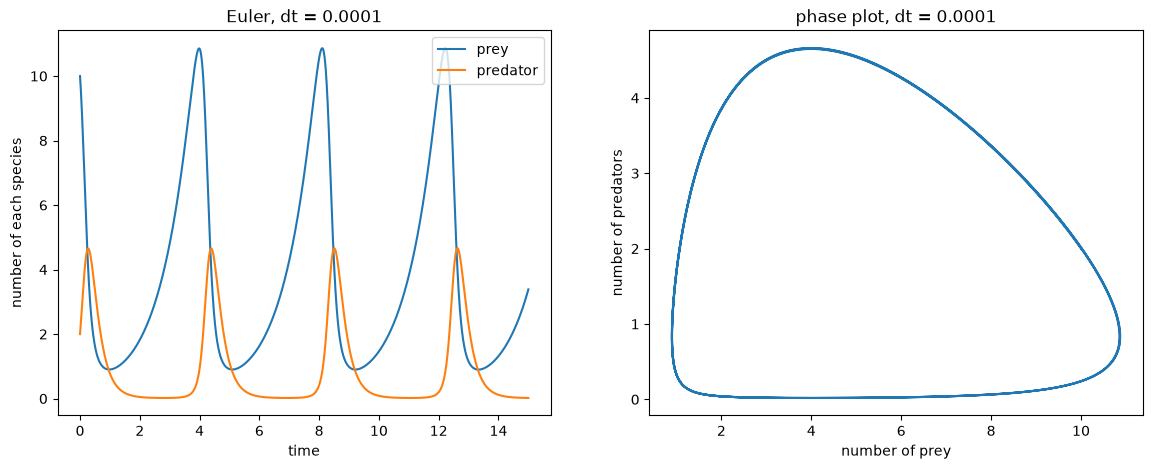

In [29]:
dt_list = [0.1, 0.01, 0.001, 0.0001]

for dt in dt_list:
    t, u = run_model(euler_step, dt)
    print(f'dt = {dt}: min prey = {u[:,0].min():.2f}, max prey = {u[:,0].max():.2f}, max predator = {u[:,1].max():.2f}')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(t, u[:,0], label='prey')
    ax1.plot(t, u[:,1], label='predator')
    ax1.set_xlabel('time')
    ax1.set_ylabel('number of each species')
    ax1.set_title(f'Euler, dt = {dt}')
    ax1.legend(loc='upper right')

    ax2.plot(u[:,0], u[:,1])
    ax2.set_xlabel('number of prey')
    ax2.set_ylabel('number of predators')
    ax2.set_title(f'phase plot, dt = {dt}')

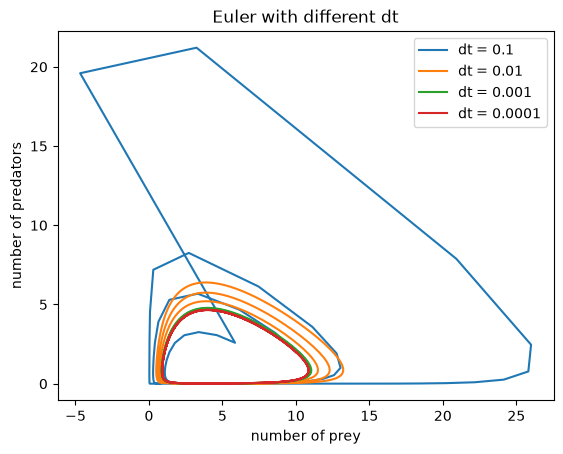

In [30]:
# all the phase plots together
for dt in dt_list:
    t, u = run_model(euler_step, dt)
    plt.plot(u[:,0], u[:,1], label=f'dt = {dt}')
plt.xlabel('number of prey')
plt.ylabel('number of predators')
plt.title('Euler with different dt')
plt.legend()

With dt = 0.1 (10x bigger) the solution falls apart. The oscillations get bigger really fast and the prey population actually goes negative (min about -4.7), which isn't possible for a real population. So dt = 0.1 is just too big for Euler's method here.

With the original dt = 0.01 it looks fine at first, but the peaks get a little bigger every cycle (max prey goes up to about 13.2 even though we started at 10). In the phase plot it spirals outward instead of making a closed loop.

With dt = 0.001 (10x smaller) the spiral is much tighter. With dt = 0.0001 (100x smaller) it's basically a closed loop and every cycle looks the same (max prey about 10.9, max predator about 4.7). The downside is that it's 150,001 steps instead of 1,501, so it takes longer to run.

So I think the growing oscillations we saw in lecture (the part in 12.2.3 that says the max population keeps increasing each cycle) are actually numerical error from Euler's method, not what the equations really do. The error goes down roughly in proportion to dt, which makes sense since Euler is first order. My understanding of why it happens: Euler uses the slope at the start of each step, and since the real solution curves around, each step lands a little bit outside the true orbit. That error adds up every cycle.

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$

Factoring:

$x(\alpha - \beta y) = 0 \rightarrow x = 0$ or $y = \alpha/\beta$

$y(\delta x - \gamma) = 0 \rightarrow y = 0$ or $x = \gamma/\delta$

If $x = 0$ then the second equation needs $y = 0$, so one steady state is $(0, 0)$. The other one is $(x, y) = (\gamma/\delta, \alpha/\beta)$, which is $(4, 0.833)$ with our parameters.

In [31]:
x_ss = gamma/delta
y_ss = alpha/beta
print('steady state:', x_ss, y_ss)
print('dx/dt and dy/dt at the steady state:', f(np.array([x_ss, y_ss])))

steady state: 4.0 0.8333333333333334
dx/dt and dy/dt at the steady state: [ 0. -0.]


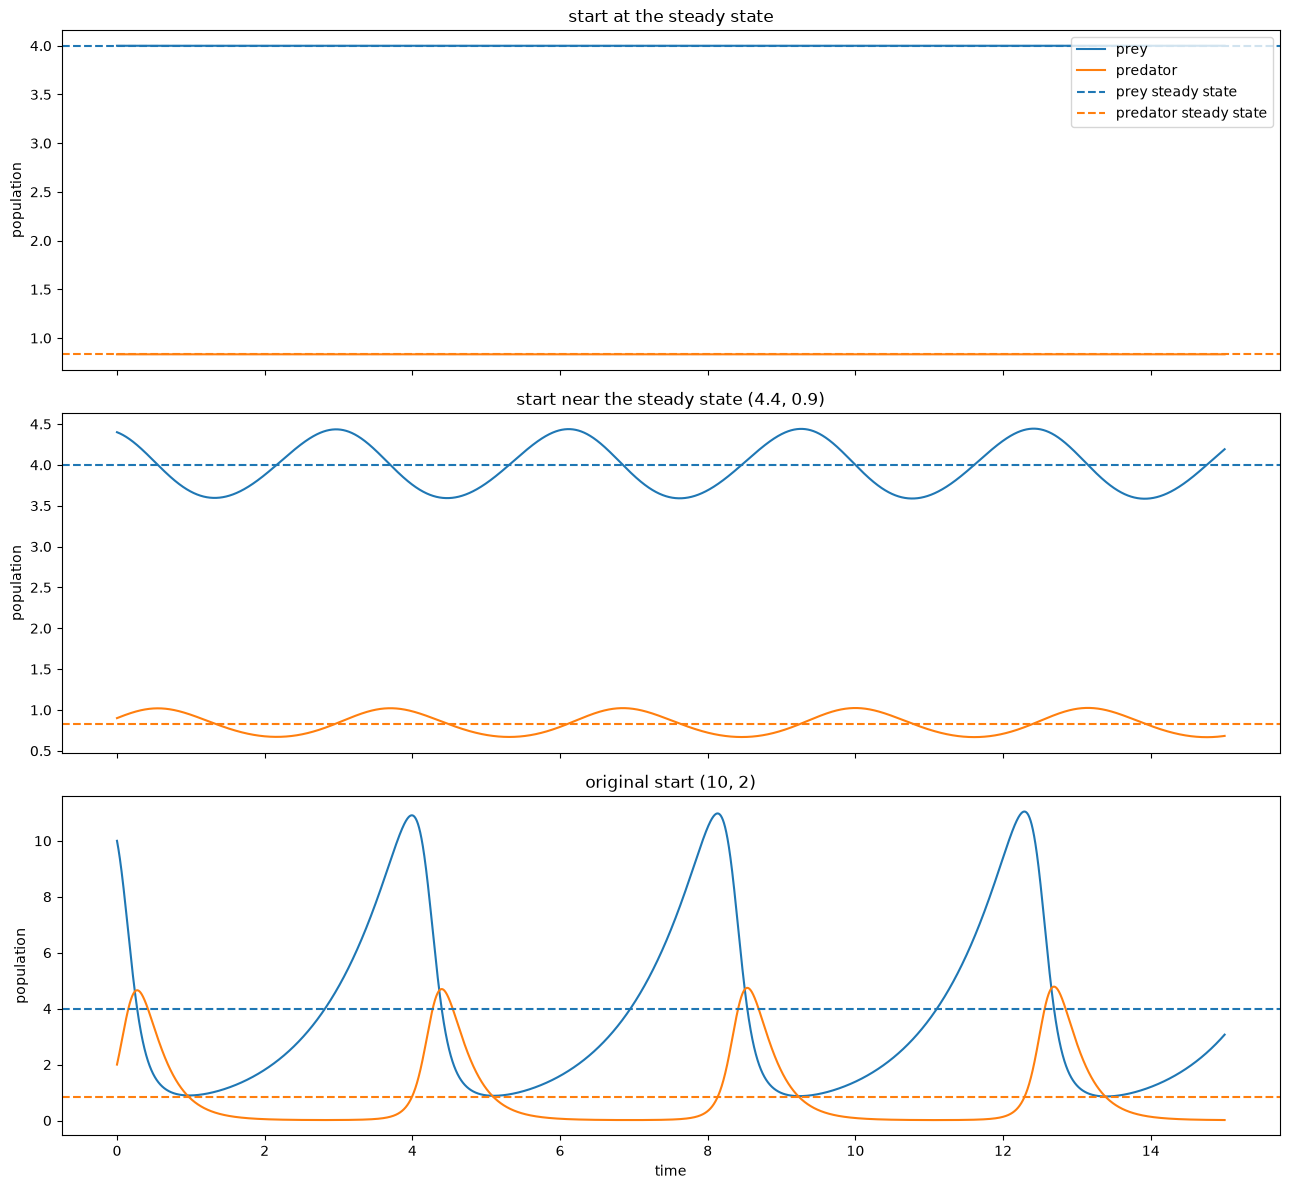

In [32]:
# start at the steady state, near it, and at the original start
# using dt = 0.001 since E.1 showed dt = 0.01 has a lot of error with Euler
starts = [(x_ss, y_ss), (4.4, 0.9), (10., 2.)]
titles = ['start at the steady state', 'start near the steady state (4.4, 0.9)', 'original start (10, 2)']

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, (x0, y0), title in zip(axes, starts, titles):   # x0, y0 change each loop so run_model uses them
    t, u = run_model(euler_step, 0.001)
    ax.plot(t, u[:,0], label='prey')
    ax.plot(t, u[:,1], label='predator')
    ax.axhline(x_ss, color='C0', linestyle='--', label='prey steady state')
    ax.axhline(y_ss, color='C1', linestyle='--', label='predator steady state')
    ax.set_title(title)
    ax.set_ylabel('population')
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('time')
plt.tight_layout()

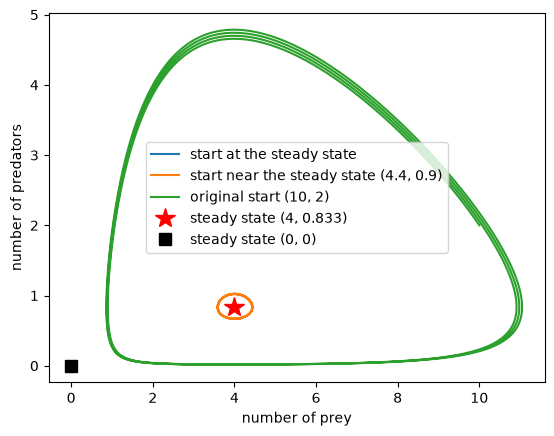

In [33]:
for (x0, y0), title in zip(starts, titles):
    t, u = run_model(euler_step, 0.001)
    plt.plot(u[:,0], u[:,1], label=title)
plt.plot(x_ss, y_ss, 'r*', markersize=15, label='steady state (4, 0.833)')
plt.plot(0, 0, 'ks', markersize=8, label='steady state (0, 0)')
plt.xlabel('number of prey')
plt.ylabel('number of predators')
plt.legend()

The steady states are (0, 0) and (γ/δ, α/β) = (4, 0.833). In the phase plot the (4, 0.833) point is right in the middle of the loops, and all the orbits go around it counterclockwise. In the timeseries the populations oscillate around the dashed steady-state lines.

If I start exactly at the steady state nothing happens. Both populations just stay constant, which makes sense because both derivatives are zero there.

If I start near it (4.4, 0.9), the populations make a small loop around the steady state. They don't move toward it or away from it, they just keep circling, and the closer I start the smaller the loop. The period of these small oscillations is a little over 3. I think that matches what you get from linearizing around the steady state, period = 2π/√(αγ) = π. Starting further away at (10, 2) gives a much bigger loop with spiky peaks and a longer period (about 4).

The other steady state (0, 0) is unstable. If there are no predators the prey just grow exponentially (dx/dt = αx), like what happened in lecture when we started with 0.001 predators. If there are no prey, the predators die off (dy/dt = -γy).

(The outer loop looks a little thick in the phase plot. I think that's just the leftover Euler error from E.1.)

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

In [34]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

dt = 0.1: min prey = 0.90, max prey = 10.85, max predator = 4.65
dt = 0.01: min prey = 0.90, max prey = 10.85, max predator = 4.65
dt = 0.001: min prey = 0.90, max prey = 10.85, max predator = 4.65


dt = 0.0001: min prey = 0.90, max prey = 10.85, max predator = 4.65


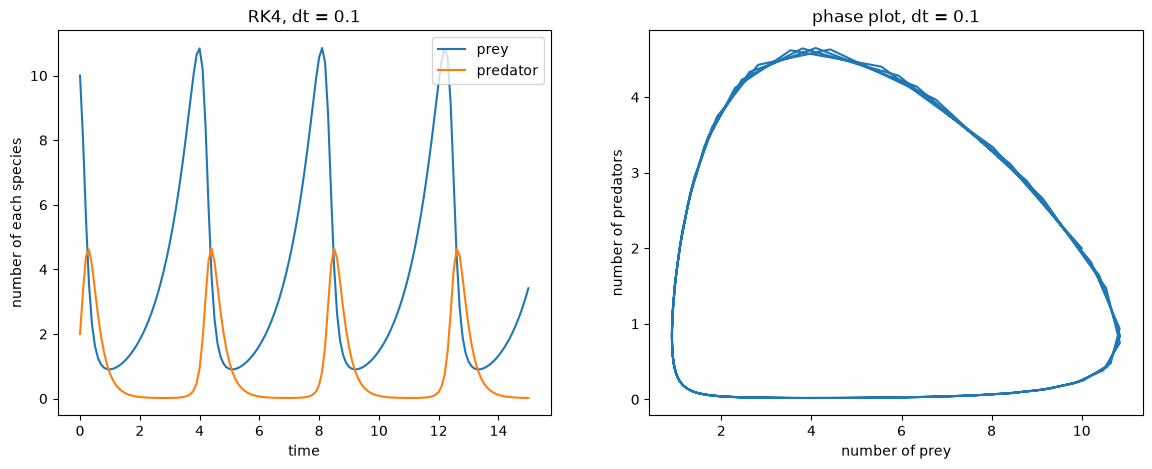

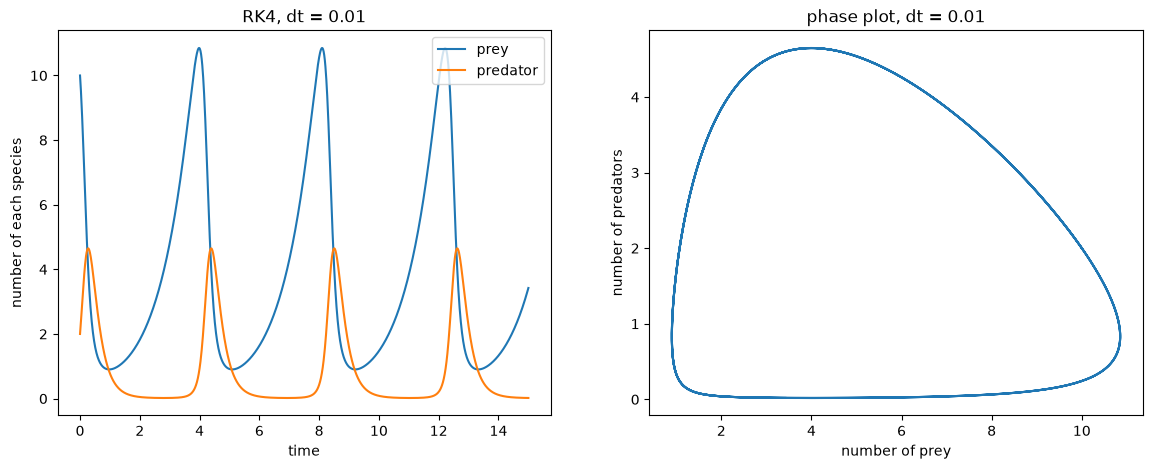

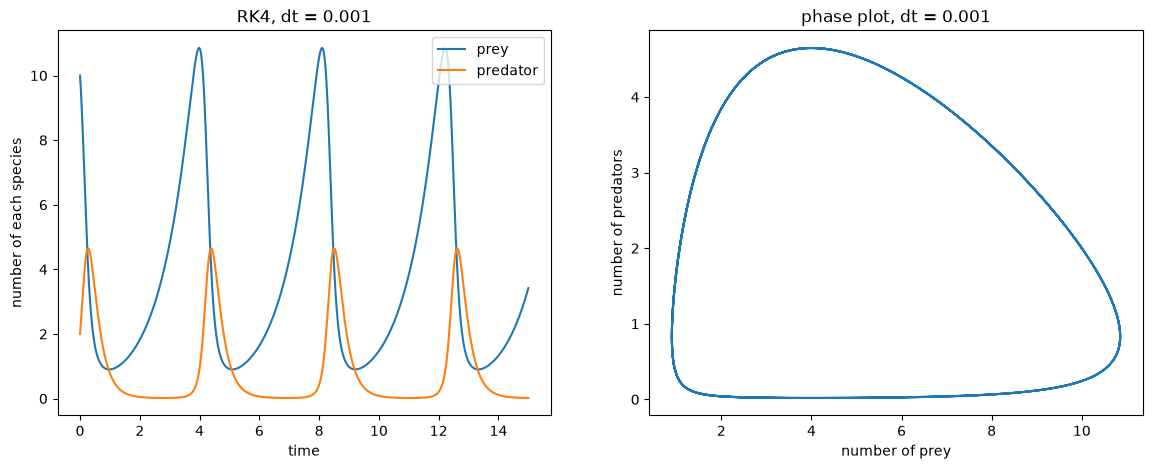

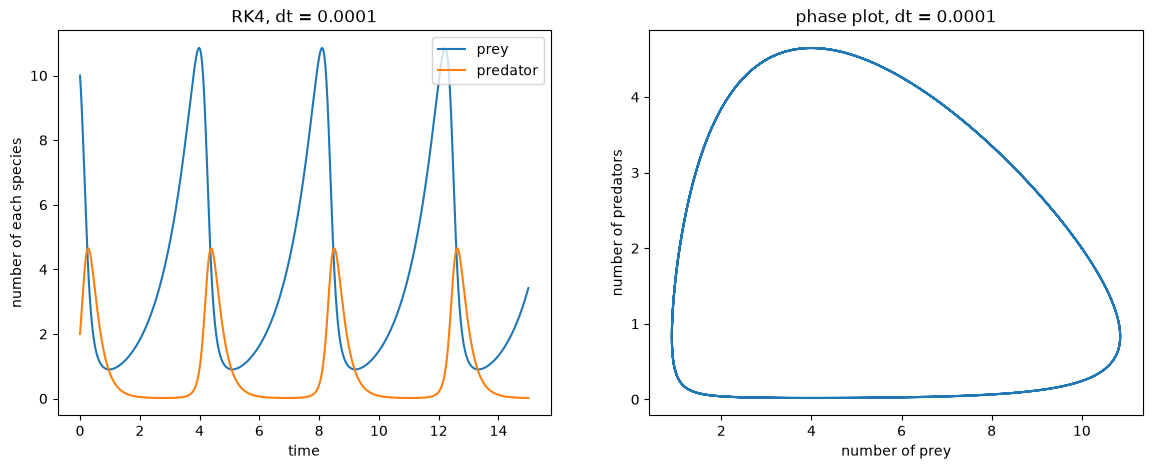

In [35]:
x0 = 10.
y0 = 2.

for dt in dt_list:
    t, u = run_model(RK4, dt)
    print(f'dt = {dt}: min prey = {u[:,0].min():.2f}, max prey = {u[:,0].max():.2f}, max predator = {u[:,1].max():.2f}')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(t, u[:,0], label='prey')
    ax1.plot(t, u[:,1], label='predator')
    ax1.set_xlabel('time')
    ax1.set_ylabel('number of each species')
    ax1.set_title(f'RK4, dt = {dt}')
    ax1.legend(loc='upper right')

    ax2.plot(u[:,0], u[:,1])
    ax2.set_xlabel('number of prey')
    ax2.set_ylabel('number of predators')
    ax2.set_title(f'phase plot, dt = {dt}')

dt = 0.1: Euler off by 2.7, RK4 off by 0.0068
dt = 0.01: Euler off by 2.5, RK4 off by 1.8e-06
dt = 0.001: Euler off by 0.35, RK4 off by 1.9e-10


dt = 0.0001: Euler off by 0.036, RK4 off by 0


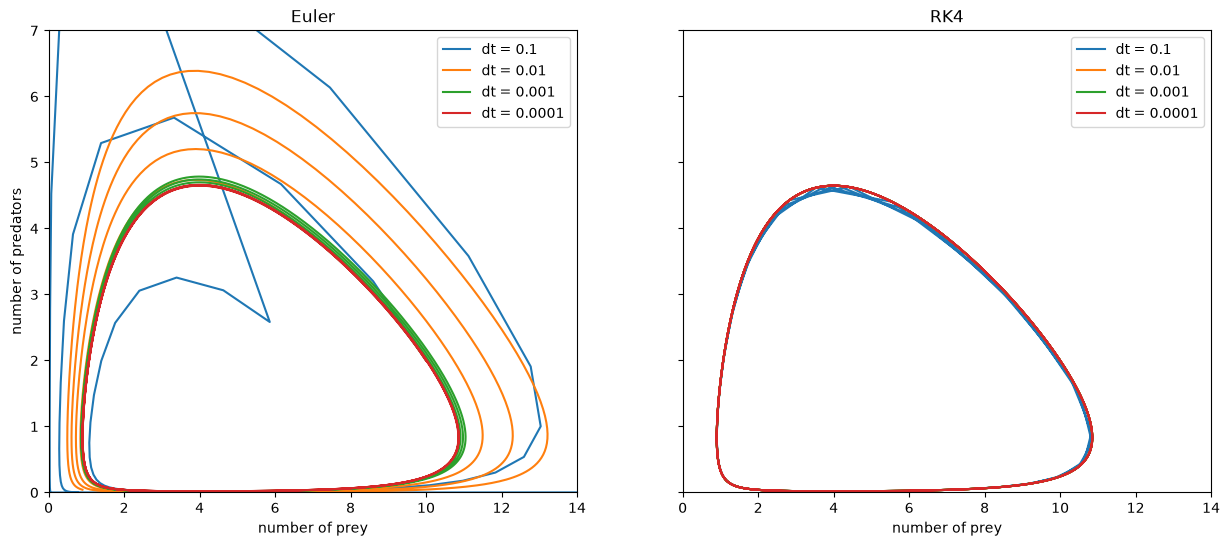

In [36]:
# Euler vs RK4 side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for dt in dt_list:
    t, u = run_model(euler_step, dt)
    ax1.plot(u[:,0], u[:,1], label=f'dt = {dt}')
    t, u = run_model(RK4, dt)
    ax2.plot(u[:,0], u[:,1], label=f'dt = {dt}')
ax1.set_title('Euler')
ax2.set_title('RK4')
for ax in (ax1, ax2):
    ax.set_xlim(0, 14)
    ax.set_ylim(0, 7)
    ax.set_xlabel('number of prey')
    ax.legend()
ax1.set_ylabel('number of predators')

# how far off is the prey at t = 15 compared to RK4 with the smallest dt?
t, u_best = run_model(RK4, 0.0001)
for dt in [0.1, 0.01, 0.001, 0.0001]:
    t, u_e = run_model(euler_step, dt)
    t, u_r = run_model(RK4, dt)
    print(f'dt = {dt}: Euler off by {abs(u_e[-1,0] - u_best[-1,0]):.2g}, RK4 off by {abs(u_r[-1,0] - u_best[-1,0]):.2g}')

RK4 is way better. Even with dt = 0.1 the phase plot is a closed loop and the peaks stay the same every cycle (max prey about 10.9, max predator about 4.65), while Euler with dt = 0.1 gave negative populations. In the side-by-side plot all four RK4 curves are pretty much on top of each other.

For RK4, changing dt barely matters. Compared to the dt = 0.0001 run, the prey at t = 15 is off by about 0.007 with dt = 0.1, about 2e-6 with dt = 0.01, and about 2e-10 with dt = 0.001. So every time dt gets 10x smaller the error drops by something like 1,000 to 10,000 times. That fits with RK4 being fourth order (error ~ dt^4). For Euler the error only drops about 10x each time.

RK4 does 4 function evaluations per step instead of 1, but it's still a lot more efficient. RK4 with dt = 0.1 (151 steps) is more accurate than Euler with dt = 0.0001 (150,001 steps). This also confirms what I said in E.1: the real solution is a closed cycle, and the growing oscillations came from Euler.

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

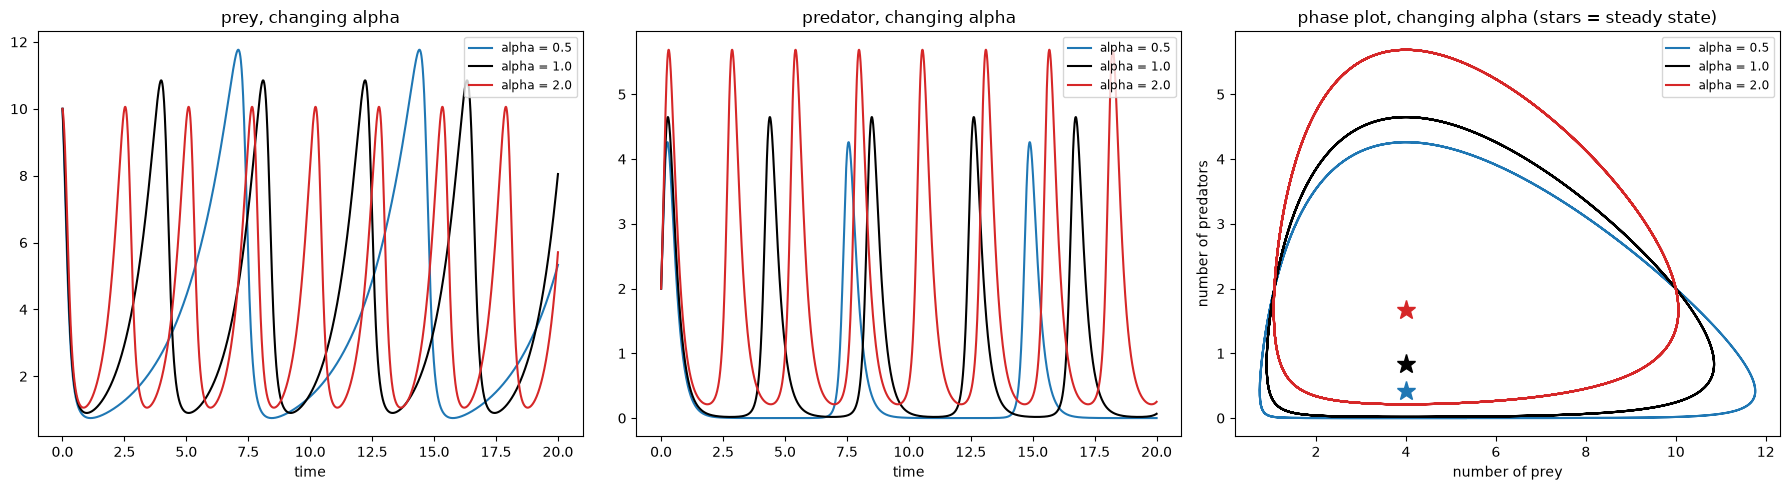

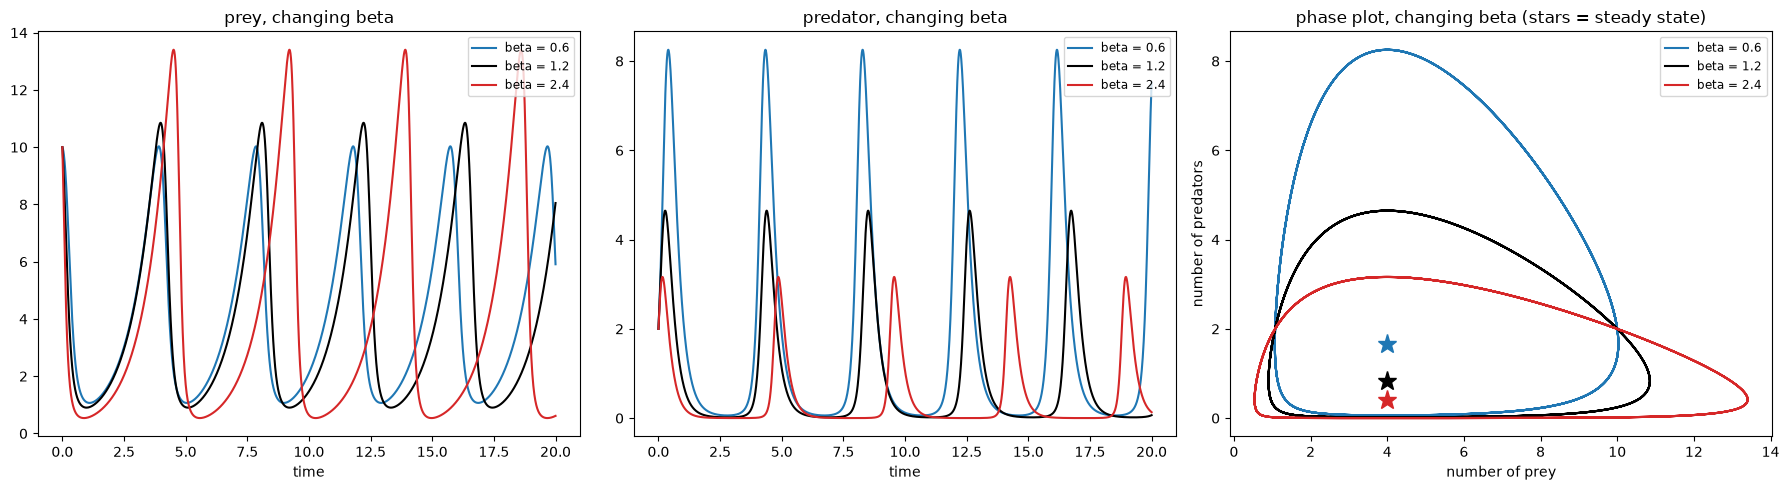

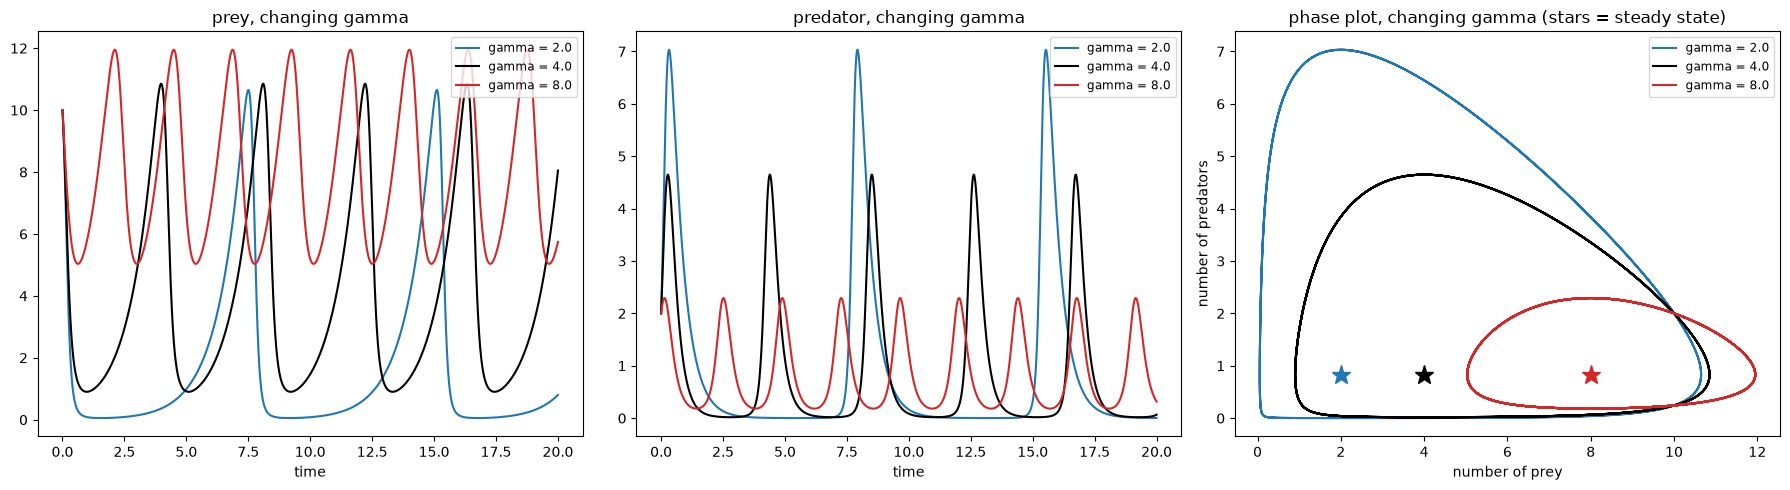

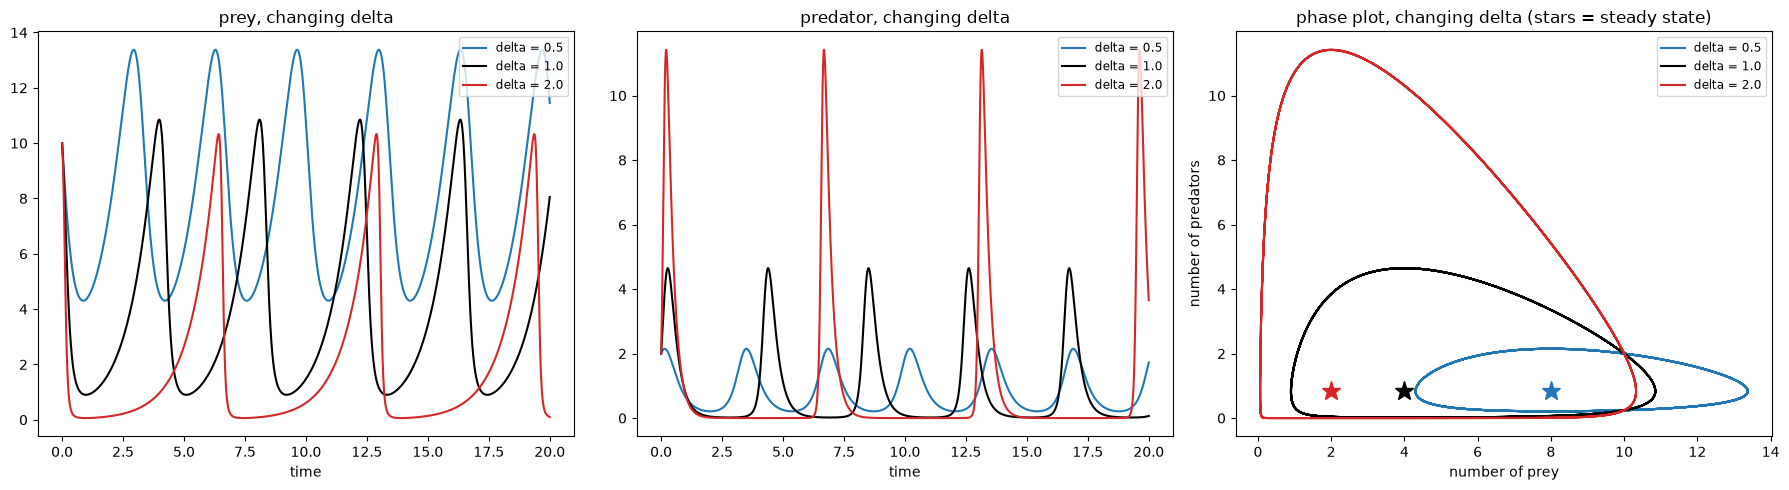

In [37]:
# change one parameter at a time (half and double), RK4 with dt = 0.01
# original: alpha = 1, beta = 1.2, gamma = 4, delta = 1
x0, y0 = 10., 2.
T = 20.0   # a bit longer to see more cycles

param_sets = {
    'alpha': [(0.5, 1.2, 4., 1.), (1., 1.2, 4., 1.), (2., 1.2, 4., 1.)],
    'beta':  [(1., 0.6, 4., 1.), (1., 1.2, 4., 1.), (1., 2.4, 4., 1.)],
    'gamma': [(1., 1.2, 2., 1.), (1., 1.2, 4., 1.), (1., 1.2, 8., 1.)],
    'delta': [(1., 1.2, 4., 0.5), (1., 1.2, 4., 1.), (1., 1.2, 4., 2.)],
}

for name, sets in param_sets.items():
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
    for (alpha, beta, gamma, delta), color in zip(sets, ['C0', 'k', 'C3']):   # f uses these
        value = {'alpha': alpha, 'beta': beta, 'gamma': gamma, 'delta': delta}[name]
        t, u = run_model(RK4, 0.01)
        ax1.plot(t, u[:,0], color=color, label=f'{name} = {value}')
        ax2.plot(t, u[:,1], color=color, label=f'{name} = {value}')
        ax3.plot(u[:,0], u[:,1], color=color, label=f'{name} = {value}')
        ax3.plot(gamma/delta, alpha/beta, '*', color=color, markersize=14)   # steady state
    ax1.set_title(f'prey, changing {name}')
    ax2.set_title(f'predator, changing {name}')
    ax3.set_title(f'phase plot, changing {name} (stars = steady state)')
    ax1.set_xlabel('time')
    ax2.set_xlabel('time')
    ax3.set_xlabel('number of prey')
    ax3.set_ylabel('number of predators')
    for ax in (ax1, ax2, ax3):
        ax.legend(loc='upper right', fontsize='small')
    plt.tight_layout()

# back to the original values
alpha, beta, gamma, delta = 1., 1.2, 4., 1.

The steady state is (γ/δ, α/β), so changing the parameters moves where the loops are centered. One thing I thought was interesting is that the prey steady state only depends on the predator parameters (γ, δ), and the predator steady state only depends on the prey parameters (α, β). How big the oscillations are also depends a lot on how far the starting point (10, 2) is from the steady state.

**α (prey growth rate):** Bigger α makes the cycles faster (roughly 7, 4, and 2.6 time units per cycle for α = 0.5, 1, 2) and the predators peak higher. The prey steady state stays at 4, but the predator steady state α/β goes up. So faster-growing prey end up supporting more predators, not more prey. With α = 0.5 the predators almost die out between peaks.

**β (predation rate):** Bigger β means each predator eats more, so the predator steady state α/β goes down. The predator peaks get smaller (about 8.3, 4.7, 3.2) but the prey swing more (up to about 13.4 with β = 2.4). Both populations also get really low at the bottom of the cycle.

**γ (predator death rate):** Bigger γ moves the prey steady state γ/δ up (2, 4, 8). Predators die faster, so it takes more prey to keep them alive. The cycles also get faster. With γ = 8 the steady state (8, 0.83) is pretty close to where we start, so the oscillations are small. With γ = 2 they're huge, and both species nearly go extinct at the low points.

**δ (how well predators turn prey into more predators):** Bigger δ moves the prey steady state down (8, 4, 2). With δ = 2 the predators boom really hard (peak about 11), then crash to almost zero, and the cycles get slower.

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

For E.5 I added a self-limiting term $-ay^2$ to the predator equation:

$dx/dt = \alpha x - \beta x y$

$dy/dt = \delta x y - \gamma y - a y^2$

This is supposed to represent competition between predators (or them eating each other). When there are a lot of predators, they start limiting themselves. Setting both equations to zero gives the new steady state: $y = \alpha/\beta$ (same as before) and $x = (\gamma + a\alpha/\beta)/\delta$. So the prey steady state goes up when $a$ gets bigger.

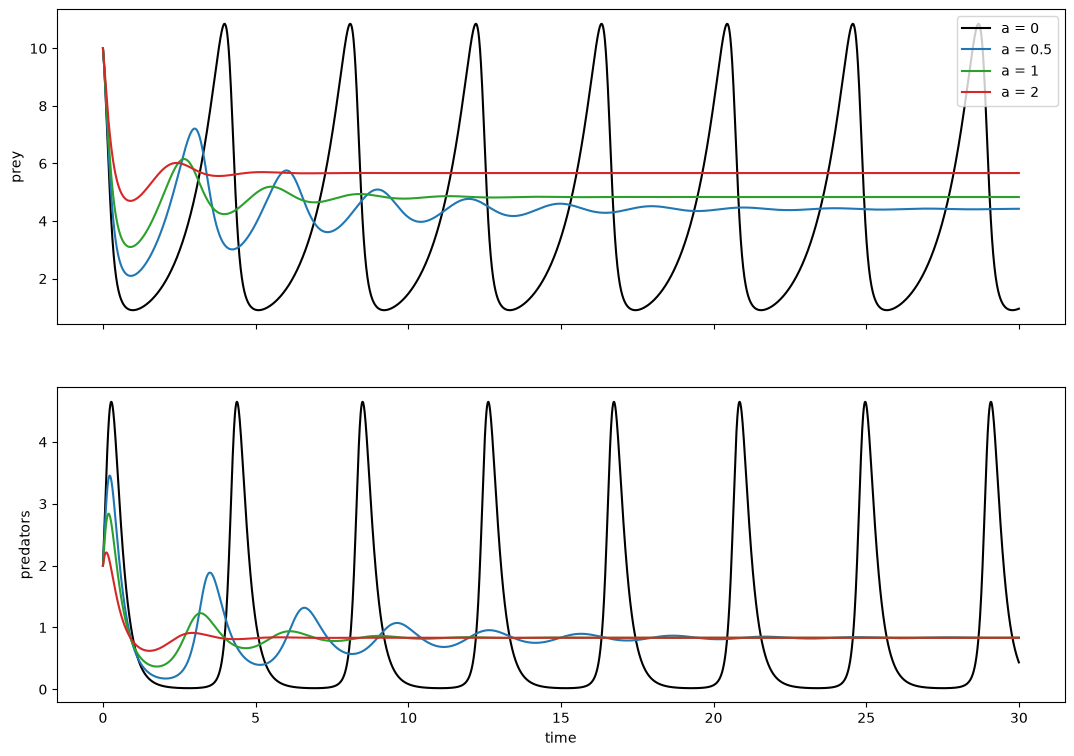

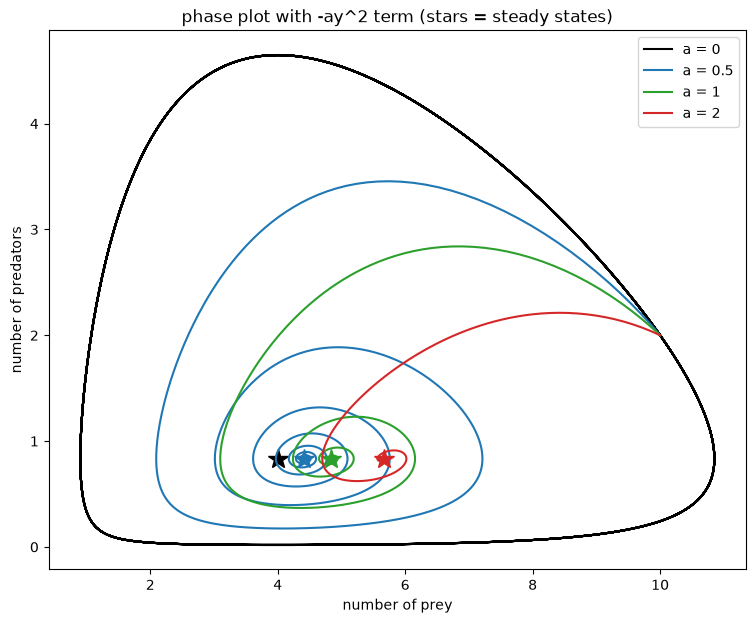

In [38]:
def f_self(u):
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x) - a*y**2])

T = 30.0
dt = 0.01
N = int(round(T/dt)) + 1
t = np.linspace(0.0, T, N)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
fig2, ax3 = plt.subplots(figsize=(9, 7))
for a, color in zip([0, 0.5, 1, 2], ['k', 'C0', 'C2', 'C3']):
    u = np.zeros((N, 2))
    u[0] = np.array([x0, y0])
    for n in range(N-1):
        u[n+1] = RK4(u[n], f_self, dt)

    x_ss = (gamma + a*alpha/beta)/delta
    y_ss = alpha/beta
    ax1.plot(t, u[:,0], color=color, label=f'a = {a}')
    ax2.plot(t, u[:,1], color=color, label=f'a = {a}')
    ax3.plot(u[:,0], u[:,1], color=color, label=f'a = {a}')
    ax3.plot(x_ss, y_ss, '*', color=color, markersize=15)

ax1.set_ylabel('prey')
ax2.set_ylabel('predators')
ax2.set_xlabel('time')
ax1.legend(loc='upper right')
ax3.set_xlabel('number of prey')
ax3.set_ylabel('number of predators')
ax3.set_title('phase plot with -ay^2 term (stars = steady states)')
ax3.legend()

In [39]:
# check stability with the Jacobian at the steady state
for a in [0, 0.5, 1, 2]:
    xs = (gamma + a*alpha/beta)/delta
    ys = alpha/beta
    J = np.array([[alpha - beta*ys, -beta*xs],
                  [delta*ys, delta*xs - gamma - 2*a*ys]])
    print(f'a = {a}: steady state = ({xs:.2f}, {ys:.2f}), eigenvalues = {np.linalg.eigvals(J).round(3)}')

a = 0: steady state = (4.00, 0.83), eigenvalues = [0.+2.j 0.-2.j]
a = 0.5: steady state = (4.42, 0.83), eigenvalues = [-0.208+2.091j -0.208-2.091j]
a = 1: steady state = (4.83, 0.83), eigenvalues = [-0.417+2.159j -0.417-2.159j]
a = 2: steady state = (5.67, 0.83), eigenvalues = [-0.833+2.23j -0.833-2.23j]


Adding the $-ay^2$ term makes the oscillations die out. With a = 0 it's the normal model and the cycle repeats forever. With a = 0.5 the peaks get smaller every cycle, and the populations spiral in to the new steady state (4.42, 0.83). The bigger a is, the faster it settles down (with a = 2 it's basically flat after t = 5). In the phase plot the closed loop turns into a spiral going into the steady state.

To check this I calculated the eigenvalues of the Jacobian at the steady state. For a = 0 they're purely imaginary (±2i), which means it's a center: it just goes around in closed loops forever. The imaginary part 2 also gives a period of 2π/2 ≈ 3.1, the same as E.2. For a > 0 the real part is negative (-0.21, -0.42, -0.83 for a = 0.5, 1, 2), so it's a stable spiral, and the oscillations decay faster as a gets bigger. Working it out by hand, the trace of the Jacobian at the steady state is $-ay^*$ and the determinant is positive, so any a > 0 makes the steady state stable.

Physically this makes sense to me. When there are lots of predators they compete with each other, so they can't overshoot as much, and the boom-bust cycles damp out. This seems more realistic than the original model, where the cycles go on forever with the exact same size.